# AI651 Assignment 2: Question 2

In [1]:
import json
import math
import os
import pathlib
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt

SMOKE = False

OUT = pathlib.Path("/kaggle/working") if pathlib.Path("/kaggle/working").exists() else pathlib.Path(".")
RUNS = OUT / "runs"
FIGS = OUT / "figures"
GIFS = OUT / "gifs"
RESULTS = OUT / "results"
for d in (RUNS, FIGS, GIFS, RESULTS):
    d.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
HARDWARE = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"

print("torch", torch.__version__)
print("device", DEVICE, "|", HARDWARE)

matplotlib.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight", "font.size": 8})


def fmt(v, sig=3):
    if v == 0:
        return "0"
    if abs(v) < 1e-3:
        return f"{v:.{sig - 1}e}"
    return f"{v:.{sig}g}"


def save_json(name, obj):
    path = RESULTS / name
    path.write_text(json.dumps(obj, indent=2, default=float))
    print("wrote", path)

torch 2.11.0+cu128
device cuda | Tesla T4


## 1. Setup

### Transformations

Pixel convention: `x[i, j]` is row *i*, column *j*, indices 0-63.
`M` reverses the column axis, `R` is a quarter turn anticlockwise.
`G = {R^a, M R^a : a = 0,1,2,3}` with `(M R^a)(x) = M(R^a(x))`, rotate first.

In [3]:
def mirror(x):
    return torch.flip(x, dims=(-1,))


def rotate(x, a=1):
    return torch.rot90(x, k=a % 4, dims=(-2, -1))


GROUP = tuple((a, m) for m in (False, True) for a in (0, 1, 2, 3))

assert len(GROUP) == 8


def group_name(a, mirrored):
    return f"{'MR' if mirrored else 'R'}{a}"


def apply_g(x, a, mirrored):
    y = rotate(x, a)
    return mirror(y) if mirrored else y


def apply_g_inv(x, a, mirrored):
    if mirrored:
        return apply_g(x, a, True)
    return rotate(x, -a)


def transform(x, which):
    if which == "M":
        return mirror(x)
    if which == "R":
        return rotate(x, 1)
    raise ValueError(which)

### Data and windows

In [4]:
from torchvision.datasets import MovingMNIST

SPLITS = {"train": (0, 8000), "val": (8000, 9000), "test": (9000, 10000)}
N_FRAMES, N_INPUT, N_TARGET, N_STEPS = 20, 5, 5, 9


def load_videos(split, root=None):
    root = root or str(OUT / "data")
    ds = MovingMNIST(root=root, split=None, download=True)
    data = getattr(ds, "data", None)
    if data is None:
        data = torch.stack([ds[i] for i in range(len(ds))])
    if tuple(data.shape[1:]) != (N_FRAMES, 1, 64, 64):
        raise RuntimeError(f"unexpected MovingMNIST layout {tuple(data.shape)}")
    lo, hi = SPLITS[split]
    return data[lo:hi]


def synthetic_videos(n, seed=0):
    g = torch.Generator().manual_seed(seed)
    v = torch.zeros(n, N_FRAMES, 1, 64, 64, dtype=torch.uint8)
    for b in range(n):
        y, x = torch.randint(8, 56, (2,), generator=g).tolist()
        dy, dx = torch.randint(-3, 4, (2,), generator=g).tolist()
        for t in range(N_FRAMES):
            r = min(max(y + dy * t, 0), 59)
            c = min(max(x + dx * t, 0), 59)
            v[b, t, 0, r:r + 5, c:c + 5] = 255
    return v


def to_float(v):
    return v.to(torch.float32) / 255.0


def window_frames(t, k):
    inputs = [t + i * k for i in range(N_INPUT)]
    targets = [t + (N_INPUT + i) * k for i in range(N_TARGET)]
    return inputs, [f for f in targets if f <= N_FRAMES]


def allowed_starts(k, protocol):
    if protocol == "normal":
        if k != 1:
            raise ValueError("normal-speed training is 1x only")
        return [t for t in range(1, N_FRAMES + 1) if t + 9 * k <= N_FRAMES]
    if protocol == "speed":
        return [
            t
            for t in range(1, N_FRAMES + 1)
            if t + 4 * k <= N_FRAMES and t + (N_INPUT + 1) * k <= N_FRAMES
        ]
    raise ValueError(protocol)


def window(video, t, k):
    inputs, targets = window_frames(t, k)
    X = video[[f - 1 for f in inputs]]
    Y = torch.zeros((N_TARGET,) + tuple(video.shape[1:]), dtype=video.dtype)
    mask = torch.zeros(N_TARGET, dtype=torch.bool)
    if targets:
        Y[: len(targets)] = video[[f - 1 for f in targets]]
        mask[: len(targets)] = True
    return X, Y, mask


def make_batch(videos, specs):
    xs, ys, ms = [], [], []
    for index, t, k, g in specs:
        X, Y, m = window(videos[index], t, k)
        X, Y = to_float(X), to_float(Y)
        if g is not None:
            X, Y = apply_g(X, *g), apply_g(Y, *g)
        xs.append(X)
        ys.append(Y)
        ms.append(m)
    return torch.stack(xs), torch.stack(ys), torch.stack(ms)


def eval_batches(videos, t=1, k=1, batch_size=32):
    for lo in range(0, len(videos), batch_size):
        hi = min(lo + batch_size, len(videos))
        yield make_batch(videos, [(i, t, k, None) for i in range(lo, hi)])


if SMOKE:
    train_videos = synthetic_videos(64, seed=0)
    val_videos = synthetic_videos(16, seed=1)
    test_videos = synthetic_videos(32, seed=2)
else:
    train_videos = load_videos("train")
    val_videos = load_videos("val")
    test_videos = load_videos("test")

print("train", tuple(train_videos.shape), train_videos.dtype)
print("val  ", tuple(val_videos.shape))
print("test ", tuple(test_videos.shape))

100%|██████████| 819M/819M [00:20<00:00, 40.7MB/s] 


train (8000, 20, 1, 64, 64) torch.uint8
val   (1000, 20, 1, 64, 64)
test  (1000, 20, 1, 64, 64)


### Table 1: checking the transformation and window functions

In [5]:
def bright_pixel(v):
    f, _, r, c = (int(i) for i in (v == v.max()).nonzero()[0])
    return f, r, c


def table1():
    torch.manual_seed(0)
    x = torch.rand(20, 1, 64, 64)
    p = torch.zeros(20, 1, 64, 64)
    p[7, 0, 10, 20] = 1.0

    rows = []
    mm = mirror(mirror(x))
    rows.append(("(a) max|M(M(x)) - x|", "0", fmt(float((mm - x).abs().max())),
                 f"torch.equal = {torch.equal(mm, x)}"))

    r4 = x
    for _ in range(4):
        r4 = rotate(r4, 1)
    rows.append(("(b) max|R^4(x) - x|", "0", fmt(float((r4 - x).abs().max())),
                 f"torch.equal = {torch.equal(r4, x)}"))

    lhs, rhs = mirror(rotate(mirror(x), 1)), rotate(x, -1)
    rows.append(("(c) max|MRM(x) - R^-1(x)|", "0", fmt(float((lhs - rhs).abs().max())),
                 f"torch.equal = {torch.equal(lhs, rhs)}"))

    rows.append(("(d) bright pixel of M(p)", "(7, 10, 43)", str(bright_pixel(mirror(p))), ""))
    rows.append(("(e) bright pixel of R(p)", "(7, 43, 10)", str(bright_pixel(rotate(p, 1))), ""))

    ramp = (torch.arange(1, 21, dtype=torch.float32)
            .view(20, 1, 1, 1).expand(20, 1, 64, 64).contiguous())
    expected_w = {1: "1-5 / 6-10", 2: "1,3,5,7,9 / 11,13,15,17,19", 3: "1,4,7,10,13 / 16,19"}
    for k in (1, 2, 3):
        inputs, targets = window_frames(1, k)
        gi = [int(v) for v in ramp[[f - 1 for f in inputs]][:, 0, 0, 0]]
        gt = [int(v) for v in ramp[[f - 1 for f in targets]][:, 0, 0, 0]]
        rows.append((f"({'fgh'[k - 1]}) {k}x input / target frames",
                     expected_w[k],
                     ",".join(map(str, gi)) + " / " + ",".join(map(str, gt)), ""))

    w0 = max(len(r[0]) for r in rows)
    w1 = max(len(r[1]) for r in rows)
    print(f"{'Check':<{w0}}  {'Expected':<{w1}}  Yours")
    for label, exp, got, note in rows:
        print(f"{label:<{w0}}  {exp:<{w1}}  {got}" + (f"   [{note}]" if note else ""))

    starts = {k: allowed_starts(k, "speed") for k in (1, 2, 3)}
    expected_s = {1: list(range(1, 15)), 2: list(range(1, 9)), 3: [1, 2]}
    print()
    for k in (1, 2, 3):
        ok = starts[k] == expected_s[k]
        print(f"speed-augmented starts at {k}x: {starts[k]}  "
              f"{'OK' if ok else 'MISMATCH expected ' + str(expected_s[k])}")
        assert ok
    print(f"normal-speed starts (A, B):   {allowed_starts(1, 'normal')}")

    save_json("table1.json", {
        "rows": [{"check": a, "expected": b, "yours": c, "note": d} for a, b, c, d in rows],
        "speed_starts": {str(k): v for k, v in starts.items()},
        "normal_starts": allowed_starts(1, "normal"),
    })


table1()

Check                         Expected                    Yours
(a) max|M(M(x)) - x|          0                           0   [torch.equal = True]
(b) max|R^4(x) - x|           0                           0   [torch.equal = True]
(c) max|MRM(x) - R^-1(x)|     0                           0   [torch.equal = True]
(d) bright pixel of M(p)      (7, 10, 43)                 (7, 10, 43)
(e) bright pixel of R(p)      (7, 43, 10)                 (7, 43, 10)
(f) 1x input / target frames  1-5 / 6-10                  1,2,3,4,5 / 6,7,8,9,10
(g) 2x input / target frames  1,3,5,7,9 / 11,13,15,17,19  1,3,5,7,9 / 11,13,15,17,19
(h) 3x input / target frames  1,4,7,10,13 / 16,19         1,4,7,10,13 / 16,19

speed-augmented starts at 1x: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]  OK
speed-augmented starts at 2x: [1, 2, 3, 4, 5, 6, 7, 8]  OK
speed-augmented starts at 3x: [1, 2]  OK
normal-speed starts (A, B):   [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
wrote /kaggle/working/results/table1.json


### Figure 1: is the training data already symmetric?

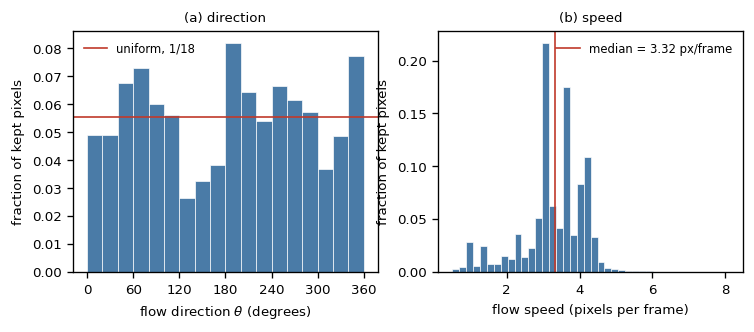

pixels kept        : 103,050 from 950 frame pairs
median speed       : 3.318 px/frame   ->  2x 6.635,  3x 9.953
90th pct speed     : 4.124 px/frame   ->  3x 12.371
max speed          : 8.107 px/frame
wrote /kaggle/working/results/figure1_stats.json


In [6]:
import cv2


def optical_flow_stats(videos, n_videos=50):
    dxs, dys = [], []
    n = min(n_videos, len(videos))
    for b in range(n):
        arr = videos[b][:, 0].numpy().astype(np.uint8)
        for s in range(N_FRAMES - 1):
            prev, nxt = arr[s], arr[s + 1]
            flow = cv2.calcOpticalFlowFarneback(prev, nxt, None, 0.5, 3, 15, 3, 5, 1.2, 0)
            dx, dy = flow[..., 0], flow[..., 1]
            mag = np.sqrt(dx ** 2 + dy ** 2)
            keep = (prev > 51) & (nxt > 51) & (mag > 0.5)
            dxs.append(dx[keep])
            dys.append(dy[keep])
    dx = np.concatenate(dxs)
    dy = np.concatenate(dys)
    theta = np.degrees(np.arctan2(-dy, dx)) % 360.0
    speed = np.sqrt(dx ** 2 + dy ** 2)
    return theta, speed, (n, (N_FRAMES - 1) * n)


def figure1(videos):
    theta, speed, (nv, npairs) = optical_flow_stats(videos, 50 if not SMOKE else 4)
    kept = theta.size
    median = float(np.median(speed))

    fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.6))
    bins = np.arange(0, 361, 20)
    ax[0].hist(theta, bins=bins, weights=np.full(kept, 1.0 / kept),
               color="#4a7ba7", edgecolor="white", linewidth=0.4)
    ax[0].axhline(1 / 18, color="#c0392b", linewidth=1.0, label="uniform, 1/18")
    ax[0].set_xlabel(r"flow direction $\theta$ (degrees)")
    ax[0].set_ylabel("fraction of kept pixels")
    ax[0].set_xticks(np.arange(0, 361, 60))
    ax[0].legend(frameon=False, fontsize=7)
    ax[0].set_title("(a) direction", fontsize=8)

    ax[1].hist(speed, bins=40, weights=np.full(kept, 1.0 / kept),
               color="#4a7ba7", edgecolor="white", linewidth=0.4)
    ax[1].axvline(median, color="#c0392b", linewidth=1.0,
                  label=f"median = {median:.2f} px/frame")
    ax[1].set_xlabel("flow speed (pixels per frame)")
    ax[1].set_ylabel("fraction of kept pixels")
    ax[1].legend(frameon=False, fontsize=7)
    ax[1].set_title("(b) speed", fontsize=8)

    fig.savefig(FIGS / "fig1_optical_flow.pdf")
    fig.savefig(FIGS / "fig1_optical_flow.png")
    plt.show()

    stats = {
        "videos": nv, "frame_pairs": npairs, "pixels_kept": int(kept),
        "median_speed": median,
        "mean_speed": float(speed.mean()),
        "speed_p90": float(np.percentile(speed, 90)),
        "speed_max": float(speed.max()),
        "median_speed_2x": 2 * median, "median_speed_3x": 3 * median,
        "p90_speed_3x": 3 * float(np.percentile(speed, 90)),
        "direction_bin_fractions": (np.histogram(theta, bins=bins)[0] / kept).tolist(),
    }
    print(f"pixels kept        : {kept:,} from {npairs} frame pairs")
    print(f"median speed       : {median:.3f} px/frame   ->  2x {2*median:.3f},  3x {3*median:.3f}")
    print(f"90th pct speed     : {stats['speed_p90']:.3f} px/frame   ->  3x {stats['p90_speed_3x']:.3f}")
    print(f"max speed          : {stats['speed_max']:.3f} px/frame")
    save_json("figure1_stats.json", stats)
    return stats


flow_stats = figure1(train_videos)

## 2. Baseline: ConvLSTM

In [7]:
class ConvLSTMCell(nn.Module):
    def __init__(self, in_ch, hid, kernel=3, dilation=1):
        super().__init__()
        self.hid = hid
        self.conv = nn.Conv2d(in_ch + hid, 4 * hid, kernel,
                              padding=dilation * (kernel - 1) // 2,
                              dilation=dilation, bias=True)

    def forward(self, u, h, c):
        i, f, o, g = self.conv(torch.cat([u, h], dim=1)).chunk(4, dim=1)
        c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)
        return h, c


class Forecaster(nn.Module):
    def __init__(self, patch=4, hid=64, dilations=(1, 1)):
        super().__init__()
        self.patch, self.hid, self.dilations = patch, hid, dilations
        cin = patch * patch
        self.cell1 = ConvLSTMCell(cin, hid, 3, dilations[0])
        self.cell2 = ConvLSTMCell(hid, hid, 3, dilations[1])
        self.head = nn.Conv2d(hid, cin, 1, bias=True)

    def forward(self, X):
        b, _, _, h, w = X.shape
        z = torch.zeros(b, self.hid, h // self.patch, w // self.patch,
                        device=X.device, dtype=X.dtype)
        h1, c1, h2, c2 = z, z.clone(), z.clone(), z.clone()
        preds = []
        for tau in range(N_STEPS):
            frame = X[:, tau] if tau < N_INPUT else preds[-1]
            u = F.pixel_unshuffle(frame, self.patch)
            h1, c1 = self.cell1(u, h1, c1)
            h2, c2 = self.cell2(h1, h2, c2)
            preds.append(torch.sigmoid(F.pixel_shuffle(self.head(h2), self.patch)))
        return torch.stack(preds[N_INPUT - 1:], dim=1)


def n_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


def build_a():
    return Forecaster(patch=4, hid=64, dilations=(1, 1))


def build_d():
    return Forecaster(patch=4, hid=64, dilations=(1, 3))


def reach_pixels(patch, dilations, kernel=3):
    return sum(d * (kernel - 1) // 2 for d in dilations) * patch


def measured_support(model):
    x = torch.zeros(1, 1, 64, 64, requires_grad=True)
    z = torch.zeros(1, model.hid, 64 // model.patch, 64 // model.patch)
    u = F.pixel_unshuffle(x, model.patch)
    h1, c1 = model.cell1(u, z, z.clone())
    h2, _ = model.cell2(h1, z.clone(), z.clone())
    out = torch.sigmoid(F.pixel_shuffle(model.head(h2), model.patch))
    g = torch.autograd.grad(out[0, 0, 32, 32], x)[0][0, 0]
    sup = g.abs() > 0
    rows = sup.any(1).nonzero().flatten()
    cols = sup.any(0).nonzero().flatten()
    r0, r1, c0, c1 = int(rows[0]), int(rows[-1]), int(cols[0]), int(cols[-1])
    solid = bool(sup[r0:r1 + 1, c0:c1 + 1].all())
    return (r0, r1, c0, c1), solid


A_PARAMS, D_PARAMS = n_params(build_a()), n_params(build_d())
D_BUDGET = int(1.5 * 480784)

print(f"model A parameters : {A_PARAMS:,}   (handout: 480,784 -> {A_PARAMS == 480784})")
print(f"model D parameters : {D_PARAMS:,}   (budget {D_BUDGET:,} -> {D_PARAMS <= D_BUDGET})")
print(f"reach A : {reach_pixels(4, (1, 1))} px/step     reach D : {reach_pixels(4, (1, 3))} px/step")
for name, mk in (("A", build_a), ("D", build_d)):
    (r0, r1, c0, c1), solid = measured_support(mk())
    print(f"  measured one-step support, model {name}: rows {r0}-{r1}, cols {c0}-{c1}, "
          f"solid block = {solid}")
assert A_PARAMS == 480784
assert D_PARAMS <= D_BUDGET
assert reach_pixels(4, (1, 3)) > reach_pixels(4, (1, 1))

save_json("architecture.json", {
    "A_params": A_PARAMS, "D_params": D_PARAMS, "D_budget": D_BUDGET,
    "A_reach_px": reach_pixels(4, (1, 1)), "D_reach_px": reach_pixels(4, (1, 3)),
    "A_dilations": [1, 1], "D_dilations": [1, 3], "patch": 4, "hidden": 64,
})

model A parameters : 480,784   (handout: 480,784 -> True)
model D parameters : 480,784   (budget 721,176 -> True)
reach A : 8 px/step     reach D : 16 px/step
  measured one-step support, model A: rows 24-43, cols 24-43, solid block = True
  measured one-step support, model D: rows 16-51, cols 16-51, solid block = True
wrote /kaggle/working/results/architecture.json


### Reference predictors and metrics

In [8]:
class BlankPredictor:
    name = "Blank"

    def __call__(self, X):
        return torch.zeros(X.shape[0], N_TARGET, *X.shape[2:],
                           device=X.device, dtype=X.dtype)

    def eval(self):
        return self


class CopyLastPredictor:
    name = "Copy-last"

    def __call__(self, X):
        return X[:, -1:].repeat(1, N_TARGET, 1, 1, 1)

    def eval(self):
        return self


class Symmetrised:
    def __init__(self, model):
        self.model = model

    def __call__(self, X):
        total = None
        for a, m in GROUP:
            p = apply_g_inv(self.model(apply_g(X, a, m)), a, m)
            total = p if total is None else total + p
        return total / len(GROUP)

    def eval(self):
        self.model.eval()
        return self


def per_horizon_mse(pred, target):
    return ((pred - target) ** 2).mean(dim=(2, 3, 4))


def masked_loss(pred, target, mask):
    per = per_horizon_mse(pred, target)
    m = mask.to(per.dtype)
    return ((per * m).sum(1) / m.sum(1).clamp_min(1)).mean()


@torch.no_grad()
def horizon_errors(f, videos, t=1, k=1, batch_size=32):
    sums = torch.zeros(N_TARGET)
    counts = torch.zeros(N_TARGET)
    for X, Y, M in eval_batches(videos, t, k, batch_size):
        X, Y = X.to(DEVICE), Y.to(DEVICE)
        per = per_horizon_mse(f(X), Y).cpu()
        m = M.to(per.dtype)
        sums += (per * m).sum(0)
        counts += m.sum(0)
    return (sums / counts.clamp_min(1)).tolist(), counts.tolist()


def E(f, videos, horizons, t=1, k=1, batch_size=32):
    mse_h, counts = horizon_errors(f, videos, t, k, batch_size)
    if any(c == 0 for c in counts[:horizons]):
        return float("nan")
    return float(np.mean(mse_h[:horizons]))


@torch.no_grad()
def consistency(f, videos, which, batch_size=32):
    c_sum, e_sum, n = 0.0, 0.0, 0
    for X, Y, _ in eval_batches(videos, 1, 1, batch_size):
        X, Y = X.to(DEVICE), Y.to(DEVICE)
        f_tx = f(transform(X, which))
        t_fx = transform(f(X), which)
        t_y = transform(Y, which)
        c_sum += float(per_horizon_mse(f_tx, t_fx).mean(1).sum())
        e_sum += float(per_horizon_mse(f_tx, t_y).mean(1).sum())
        n += X.shape[0]
    return c_sum / n, e_sum / n

### Training(A)

In [14]:
MODELS = {
    "A": dict(build=build_a, protocol="normal", symmetry=False,
              label="baseline, 1x only, no augmentation"),
    "B": dict(build=build_a, protocol="normal", symmetry=True,
              label="baseline, 1x only, symmetry augmentation"),
    "C": dict(build=build_a, protocol="speed", symmetry=False,
              label="baseline, speeds 1-3x, no augmentation"),
    "D": dict(build=build_d, protocol="speed", symmetry=False,
              label="dilation (1,3), speeds 1-3x, no augmentation"),
}

TRAIN_DB = False
if TRAIN_DB:
    MODELS["D+B"] = dict(build=build_d, protocol="speed", symmetry=True,
                         label="dilation (1,3), speeds 1-3x, symmetry augmentation")

SEEDS = (0, 1)
EPOCHS = 2 if SMOKE else 30
BATCH = 32
LR = 1e-3


def sample_specs(indices, protocol, symmetry, gen):
    specs = []
    for i in indices:
        k = 1 if protocol == "normal" else int(torch.randint(1, 4, (1,), generator=gen))
        starts = allowed_starts(k, protocol)
        t = starts[int(torch.randint(len(starts), (1,), generator=gen))]
        g = GROUP[int(torch.randint(8, (1,), generator=gen))] if symmetry else None
        specs.append((i, t, k, g))
    return specs


def train_one(name, seed):
    spec = MODELS[name]
    ckpt = RUNS / f"{name.replace('+', 'plus')}_s{seed}.pt"
    if ckpt.exists():
        saved = torch.load(ckpt, map_location="cpu", weights_only=False)
        model = spec["build"]()
        model.load_state_dict(saved["state_dict"])
        print(f"model {name} seed {seed}: loaded existing checkpoint "
              f"({saved['mean_epoch_seconds']:.1f} s/epoch)")
        return model.to(DEVICE).eval(), saved

    torch.manual_seed(seed)
    model = spec["build"]().to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    gen = torch.Generator().manual_seed(seed)
    n = len(train_videos)
    epoch_times, epoch_losses = [], []

    for epoch in range(EPOCHS):
        model.train()
        t0 = time.time()
        perm = torch.randperm(n, generator=gen).tolist()
        running, nb = 0.0, 0
        for lo in range(0, n, BATCH):
            idx = perm[lo:lo + BATCH]
            X, Y, M = make_batch(train_videos,
                                 sample_specs(idx, spec["protocol"], spec["symmetry"], gen))
            X, Y, M = X.to(DEVICE), Y.to(DEVICE), M.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss = masked_loss(model(X), Y, M)
            loss.backward()
            opt.step()
            running += float(loss.detach())
            nb += 1
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        epoch_times.append(time.time() - t0)
        epoch_losses.append(running / max(nb, 1))
        print(f"model {name} seed {seed}  epoch {epoch + 1:2d}/{EPOCHS}  "
              f"loss {epoch_losses[-1]:.5f}  {epoch_times[-1]:.1f} s", flush=True)

    saved = {
        "state_dict": {k: v.cpu() for k, v in model.state_dict().items()},
        "name": name, "seed": seed, "epochs": EPOCHS,
        "protocol": spec["protocol"], "symmetry": spec["symmetry"],
        "label": spec["label"], "params": n_params(model),
        "epoch_seconds": epoch_times,
        "mean_epoch_seconds": float(np.mean(epoch_times)),
        "epoch_losses": epoch_losses,
        "hardware": HARDWARE,
    }
    torch.save(saved, ckpt)
    print(f"model {name} seed {seed}: saved {ckpt.name}, "
          f"mean {saved['mean_epoch_seconds']:.1f} s/epoch")
    return model.eval(), saved


@torch.no_grad()
def inference_seconds(f, videos, batch_size=32):
    staged = [X.to(DEVICE) for X, _, _ in eval_batches(videos, 1, 1, batch_size)]
    f(staged[0])
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()
    for X in staged:
        f(X)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    return time.time() - t0


TRAINED = {}
META = {}


def train_group(names):
    for name in names:
        for seed in SEEDS:
            TRAINED[(name, seed)], META[(name, seed)] = train_one(name, seed)
    print("\ntrained so far:", sorted({k[0] for k in TRAINED}))


train_group(["A"])

model A seed 0: loaded existing checkpoint (11.9 s/epoch)
model A seed 1: loaded existing checkpoint (12.9 s/epoch)

trained so far: ['A']


## 3. Testing the baseline

In [12]:
import imageio.v2 as imageio


def entry(values):
    if len(values) == 1:
        return fmt(values[0])
    return f"{fmt(float(np.mean(values)))} ({', '.join(fmt(v) for v in values)})"


def show_table(title, header, rows):
    widths = [max(len(str(r[i])) for r in [header] + rows) for i in range(len(header))]
    line = "  ".join(str(h).ljust(w) for h, w in zip(header, widths))
    print(title)
    print(line)
    print("-" * len(line))
    for r in rows:
        print("  ".join(str(c).ljust(w) for c, w in zip(r, widths)))
    print()


def overlap_score(video, frames=10):
    bright = (video[:, 0].to(torch.float32) / 255.0 > 0.2).sum(dim=(1, 2)).to(torch.float32)
    med = float(bright.median())
    return 1.0 - float(bright[:frames].min()) / max(med, 1.0)


def overlap_scores(videos):
    return np.array([overlap_score(videos[i]) for i in range(len(videos))])


@torch.no_grad()
def per_video_consistency(f, videos, which, batch_size=32):
    cs, es = [], []
    for X, Y, _ in eval_batches(videos, 1, 1, batch_size):
        X, Y = X.to(DEVICE), Y.to(DEVICE)
        f_tx = f(transform(X, which))
        t_fx = transform(f(X), which)
        t_y = transform(Y, which)
        cs.append(per_horizon_mse(f_tx, t_fx).mean(1).cpu())
        es.append(per_horizon_mse(f_tx, t_y).mean(1).cpu())
    return torch.cat(cs).numpy(), torch.cat(es).numpy()


@torch.no_grad()
def predict_one(f, videos, index, t=1, k=1):
    X, Y, M = make_batch(videos, [(index, t, k, None)])
    return X.to(DEVICE), Y.to(DEVICE), M, f(X.to(DEVICE))


def grid_image(rows, pad=2):
    nr, nc = len(rows), len(rows[0])
    h = w = 64
    img = np.ones((nr * (h + pad) - pad, nc * (w + pad) - pad), dtype=np.float32)
    for i, row in enumerate(rows):
        for j, cell in enumerate(row):
            img[i * (h + pad):i * (h + pad) + h, j * (w + pad):j * (w + pad) + w] = cell
    return img


@torch.no_grad()
def consistency_panel(f, videos, index, which):
    X, Y, _, fX = predict_one(f, videos, index)
    TX, TY, TfX = transform(X, which), transform(Y, which), transform(fX, which)
    fTX = f(TX)
    g = lambda v: v[0, :, 0].cpu().numpy()
    return [
        list(g(X)) + list(g(fX)),
        list(g(TX)) + list(g(TY)),
        list(g(TX)) + list(g(fTX)),
        list(g(TX)) + list(g(TfX)),
    ]


PANEL_ROWS = [r"row 1: $X$ | $f(X)$", r"row 2: $T(X)$ | $T(Y)$",
              r"row 3: $T(X)$ | $f(T(X))$", r"row 4: $T(X)$ | $T(f(X))$"]


def draw_panel(panel, title, path):
    fig, axes = plt.subplots(4, 10, figsize=(10, 4.4))
    for i in range(4):
        for j in range(10):
            axes[i, j].imshow(panel[i][j], cmap="gray", vmin=0, vmax=1)
            axes[i, j].set_xticks([])
            axes[i, j].set_yticks([])
            if i == 0:
                axes[i, j].set_title(f"{j + 1}", fontsize=6)
        axes[i, 0].set_ylabel(PANEL_ROWS[i], fontsize=6, rotation=0,
                              ha="right", va="center", labelpad=40)
    fig.suptitle(title, fontsize=9)
    fig.savefig(path)
    fig.savefig(str(path).replace(".pdf", ".png"))
    plt.show()


def write_panel_gif(panel, path, ms_per_frame=600):
    frames = []
    for h in range(5):
        rows = [row[:5] + [row[5 + h]] for row in panel]
        img = grid_image(rows)
        frames.append((np.clip(img, 0, 1) * 255).astype(np.uint8))
    imageio.mimsave(path, frames, duration=ms_per_frame, loop=0)
    return path


OVERLAP = overlap_scores(test_videos)
print("overlap score: max", f"{OVERLAP.max():.3f}", "median", f"{np.median(OVERLAP):.3f}")

overlap score: max 0.341 median 0.086


### Table 2 and Figure 2

Table 2: per-horizon MSE, E(5) and parameter count on the 1,000 test videos (1x, t=1)
           MSE_1                    MSE_2                    MSE_3                    MSE_4                    MSE_5                    E(5)                     params 
------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Model A    0.0171 (0.0173, 0.0168)  0.0205 (0.0209, 0.0201)  0.0228 (0.0233, 0.0223)  0.0246 (0.0251, 0.0241)  0.0263 (0.0268, 0.0259)  0.0223 (0.0227, 0.0218)  480,784
Blank      0.0426                   0.0426                   0.0426                   0.0425                   0.0425                   0.0426                   0      
Copy-last  0.0492                   0.0604                   0.0669                   0.0708                   0.0732                   0.0641                   0      

wrote /kaggle/working/results/table2.json


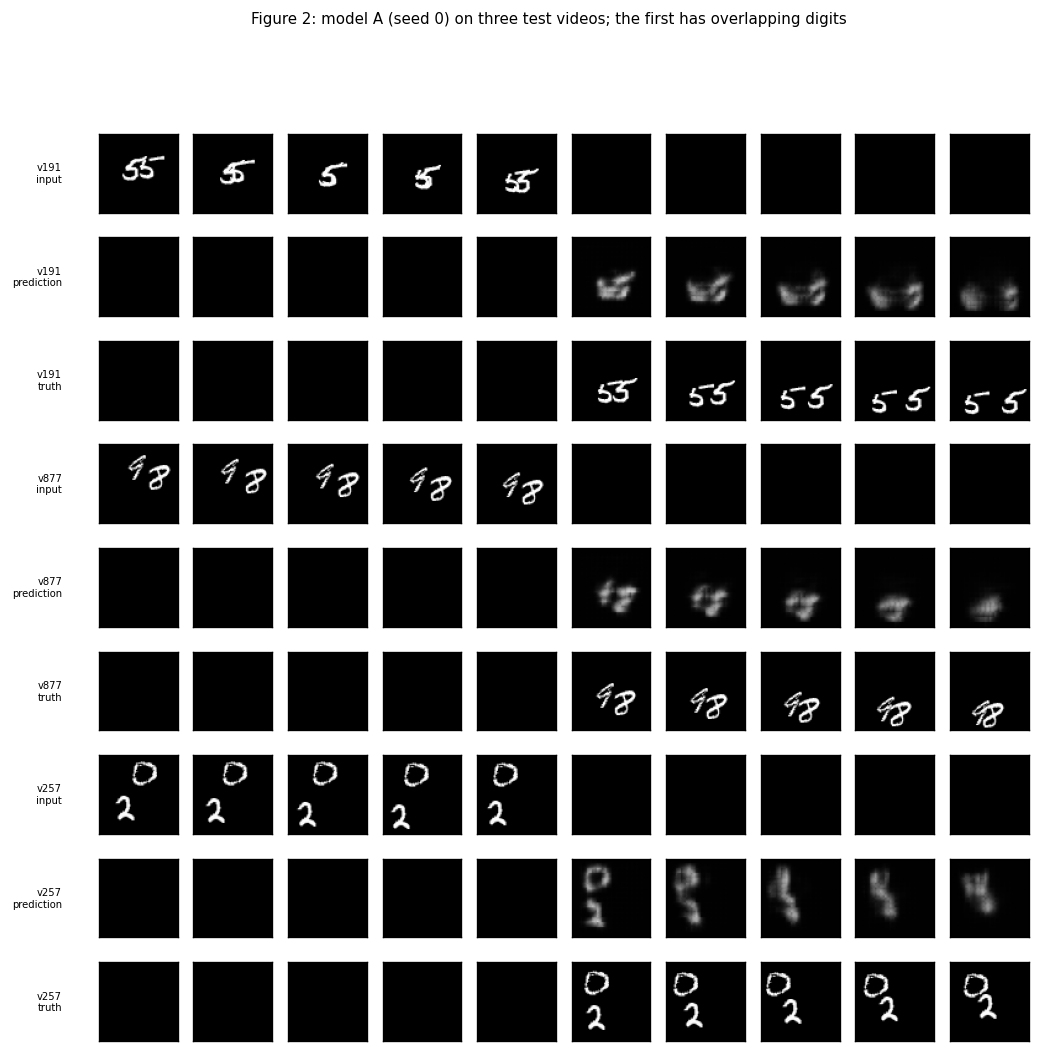

Figure 2 videos: [191, 877, 257] overlap scores: [0.341, -0.075, -0.046]


In [13]:
BLANK, COPY = BlankPredictor(), CopyLastPredictor()

a_horizons = [horizon_errors(TRAINED[("A", s)], test_videos)[0] for s in SEEDS]
blank_h = horizon_errors(BLANK, test_videos)[0]
copy_h = horizon_errors(COPY, test_videos)[0]

table2_rows = []
for label, hs, params in (
    ("Model A", a_horizons, [A_PARAMS]),
    ("Blank", [blank_h], [0]),
    ("Copy-last", [copy_h], [0]),
):
    cells = [entry([h[i] for h in hs]) for i in range(5)]
    e5 = entry([float(np.mean(h)) for h in hs])
    table2_rows.append([label] + cells + [e5, f"{params[0]:,}"])

show_table("Table 2: per-horizon MSE, E(5) and parameter count on the 1,000 test videos (1x, t=1)",
           ["", "MSE_1", "MSE_2", "MSE_3", "MSE_4", "MSE_5", "E(5)", "params"],
           table2_rows)
save_json("table2.json", {"model_A_horizons": a_horizons, "blank": blank_h, "copy_last": copy_h,
                          "A_params": A_PARAMS})

fa = TRAINED[("A", 0)]
fig2_idx = [int(np.argmax(OVERLAP))]
fig2_idx += [int(i) for i in np.argsort(OVERLAP) if int(i) not in fig2_idx][:2]
fig, axes = plt.subplots(len(fig2_idx) * 3, 10, figsize=(10, 1.1 * len(fig2_idx) * 3))
for r, idx in enumerate(fig2_idx):
    X, Y, _, P = predict_one(fa, test_videos, idx)
    strips = [(list(X[0, :, 0].cpu().numpy()) + [np.zeros((64, 64))] * 5, "input"),
              ([np.zeros((64, 64))] * 5 + list(P[0, :, 0].cpu().numpy()), "prediction"),
              ([np.zeros((64, 64))] * 5 + list(Y[0, :, 0].cpu().numpy()), "truth")]
    for s, (strip, lbl) in enumerate(strips):
        row = r * 3 + s
        for j in range(10):
            axes[row, j].imshow(strip[j], cmap="gray", vmin=0, vmax=1)
            axes[row, j].set_xticks([])
            axes[row, j].set_yticks([])
        axes[row, 0].set_ylabel(f"v{idx}\n{lbl}", fontsize=6, rotation=0, ha="right", va="center", labelpad=22)
fig.suptitle("Figure 2: model A (seed 0) on three test videos; the first has overlapping digits", fontsize=9)
fig.savefig(FIGS / "fig2_predictions.pdf")
fig.savefig(FIGS / "fig2_predictions.png")
plt.show()
print("Figure 2 videos:", fig2_idx, "overlap scores:", [round(float(OVERLAP[i]), 3) for i in fig2_idx])

### Table 3, Figure 3 and Figure 4

Table 3: consistency gaps and transformed errors (1x, t=1, 1,000 test videos)
           E(5)                     C_M                         E_M                      C_R                         E_R                    
--------------------------------------------------------------------------------------------------------------------------------------------
Model A    0.0223 (0.0227, 0.0218)  0.00174 (0.00145, 0.00203)  0.0229 (0.0232, 0.0225)  0.00293 (0.00237, 0.00349)  0.0239 (0.0241, 0.0238)
Blank      0.0426                   0                           0.0426                   0                           0.0426                 
Copy-last  0.0641                   0                           0.0641                   0                           0.0641                 

wrote /kaggle/working/results/table3.json
largest per-video C_M: [(642, '0.00375'), (279, '0.00346')]
largest per-video C_R: [(168, '0.00572'), (925, '0.00547')]


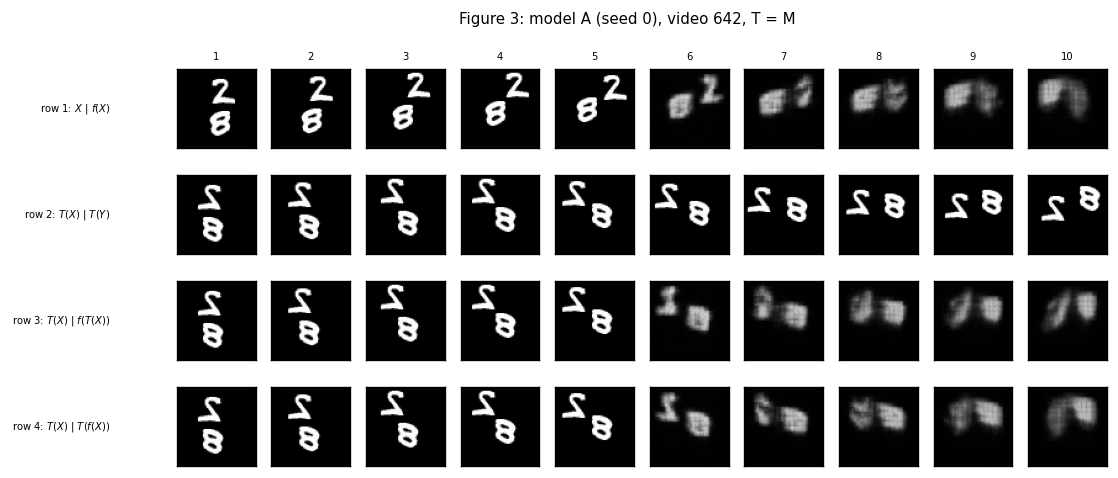

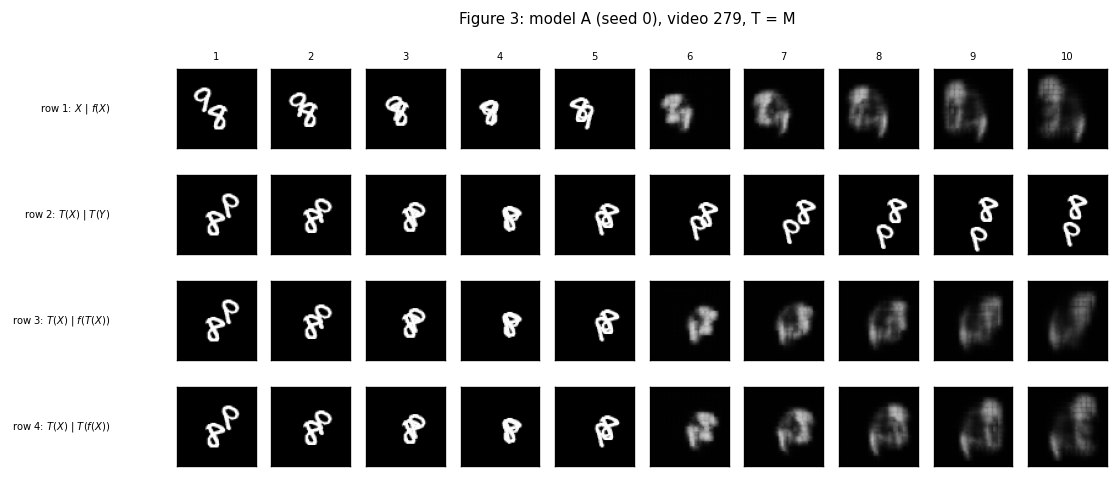

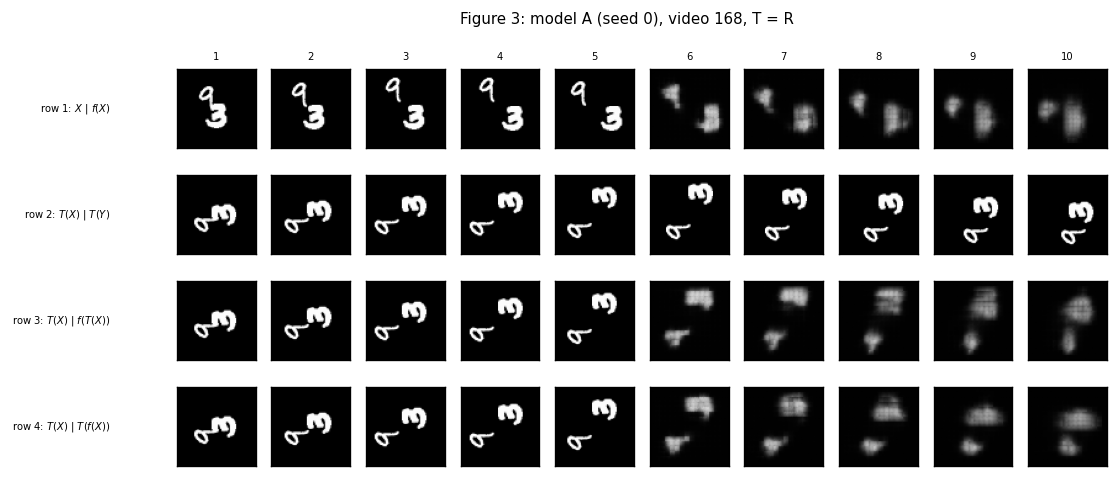

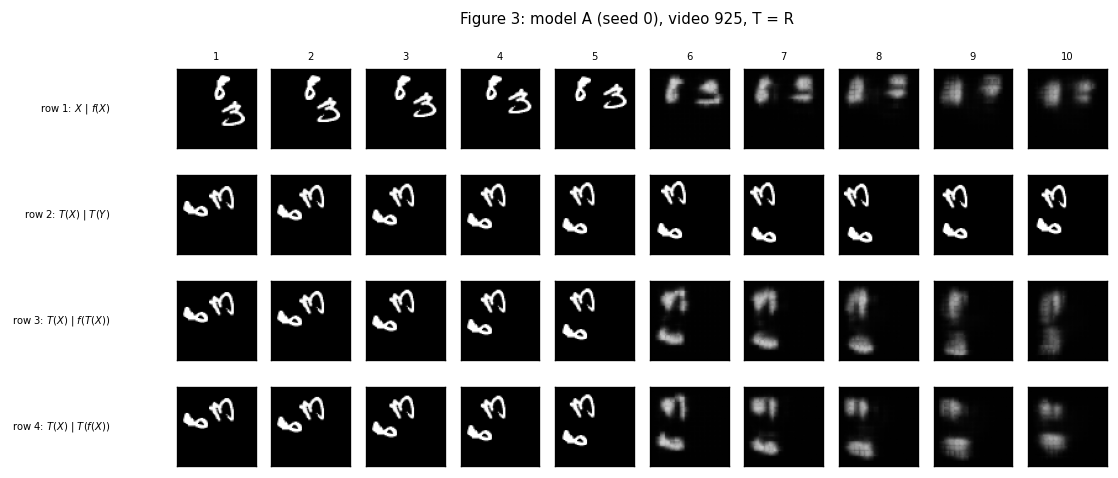

GIFs: ['gifs/fig3_v642_M.gif', 'gifs/fig3_v279_M.gif', 'gifs/fig3_v168_R.gif', 'gifs/fig3_v925_R.gif']


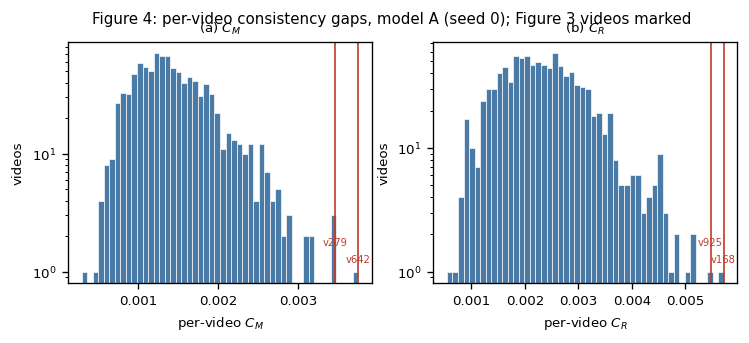

wrote /kaggle/working/results/figure4_per_video.json


In [25]:
cons = {}
for s in SEEDS:
    for which in ("M", "R"):
        cons[(s, which)] = consistency(TRAINED[("A", s)], test_videos, which)

ref_cons = {}
for pred, label in ((BLANK, "Blank"), (COPY, "Copy-last")):
    for which in ("M", "R"):
        ref_cons[(label, which)] = consistency(pred, test_videos, which)

table3_rows = [[
    "Model A",
    entry([float(np.mean(h)) for h in a_horizons]),
    entry([cons[(s, "M")][0] for s in SEEDS]), entry([cons[(s, "M")][1] for s in SEEDS]),
    entry([cons[(s, "R")][0] for s in SEEDS]), entry([cons[(s, "R")][1] for s in SEEDS]),
]]
for pred_h, label in ((blank_h, "Blank"), (copy_h, "Copy-last")):
    table3_rows.append([
        label, entry([float(np.mean(pred_h))]),
        entry([ref_cons[(label, "M")][0]]), entry([ref_cons[(label, "M")][1]]),
        entry([ref_cons[(label, "R")][0]]), entry([ref_cons[(label, "R")][1]]),
    ])

show_table("Table 3: consistency gaps and transformed errors (1x, t=1, 1,000 test videos)",
           ["", "E(5)", "C_M", "E_M", "C_R", "E_R"], table3_rows)
save_json("table3.json", {"model_A": {k[1] + f"_seed{k[0]}": v for k, v in cons.items()},
                          "reference": {f"{k[0]}_{k[1]}": v for k, v in ref_cons.items()}})

cm_vec, _ = per_video_consistency(fa, test_videos, "M")
cr_vec, _ = per_video_consistency(fa, test_videos, "R")
top_m = np.argsort(-cm_vec)[:2].tolist()
top_r = np.argsort(-cr_vec)[:2].tolist()
print("largest per-video C_M:", [(int(i), fmt(float(cm_vec[i]))) for i in top_m])
print("largest per-video C_R:", [(int(i), fmt(float(cr_vec[i]))) for i in top_r])

FIG3_CASES = [(int(i), "M") for i in top_m] + [(int(i), "R") for i in top_r]
gif_paths = []
for idx, which in FIG3_CASES:
    panel = consistency_panel(fa, test_videos, idx, which)
    tag = f"v{idx}_{which}"
    draw_panel(panel, f"Figure 3: model A (seed 0), video {idx}, T = {which}",
               FIGS / f"fig3_{tag}.pdf")
    gif_paths.append(write_panel_gif(panel, GIFS / f"fig3_{tag}.gif"))
print("GIFs:", [str(p.relative_to(OUT)) for p in gif_paths])

fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.6))
for ax, vec, which, marks in ((axes[0], cm_vec, "M", top_m), (axes[1], cr_vec, "R", top_r)):
    ax.hist(vec, bins=50, color="#4a7ba7", edgecolor="white", linewidth=0.4)
    ax.set_yscale("log")
    for i in marks:
        ax.axvline(vec[i], color="#c0392b", linewidth=1.0)
        ax.annotate(f"v{i}", (vec[i], 1), xytext=(0, 6 + 10 * marks.index(i)),
                    textcoords="offset points", ha="center", fontsize=6, color="#c0392b")
    ax.set_xlabel(f"per-video $C_{which}$")
    ax.set_ylabel("videos")
    ax.set_title(f"({'ab'[0 if which == 'M' else 1]}) $C_{which}$", fontsize=8)
fig.suptitle("Figure 4: per-video consistency gaps, model A (seed 0); Figure 3 videos marked", fontsize=9)
fig.savefig(FIGS / "fig4_consistency_hist.pdf")
fig.savefig(FIGS / "fig4_consistency_hist.png")
plt.show()
save_json("figure4_per_video.json", {"C_M": cm_vec.tolist(), "C_R": cr_vec.tolist(),
                                     "top_M": top_m, "top_R": top_r})

### Table 4 and Figure 5

Across speeds only the first two forecast horizons are comparable, since at 3x with
t=1 only two target frames exist.

Table 4: model A across speeds (1,000 test videos, t=1)
           E(2) 1x                  E(2) 2x                  E(2) 3x                  E(5) 1x                  E(5) 2x                
--------------------------------------------------------------------------------------------------------------------------------------
Model A    0.0188 (0.0191, 0.0184)  0.0449 (0.0437, 0.0461)  0.0523 (0.0512, 0.0535)  0.0223 (0.0227, 0.0218)  0.0497 (0.0474, 0.0519)
Blank      0.0426                   0.0425                   0.0426                   0.0426                   0.0425                 
Copy-last  0.0548                   0.0661                   0.0703                   0.0641                   0.0719                 

wrote /kaggle/working/results/table4.json


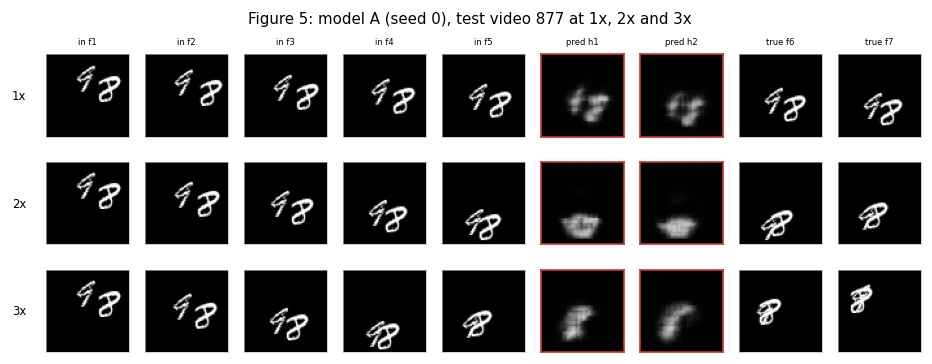

Figure 5 video: 877 overlap score -0.075


In [24]:
speed_A = {k: [E(TRAINED[("A", s)], test_videos, 2, t=1, k=k) for s in SEEDS] for k in (1, 2, 3)}
e5_A = {k: [E(TRAINED[("A", s)], test_videos, 5, t=1, k=k) for s in SEEDS] for k in (1, 2)}
speed_copy = {k: [E(COPY, test_videos, 2, t=1, k=k)] for k in (1, 2, 3)}
e5_copy = {k: [E(COPY, test_videos, 5, t=1, k=k)] for k in (1, 2)}
blank_speed = {k: [E(BLANK, test_videos, 2, t=1, k=k)] for k in (1, 2, 3)}
blank_e5 = {k: [E(BLANK, test_videos, 5, t=1, k=k)] for k in (1, 2)}

show_table("Table 4: model A across speeds (1,000 test videos, t=1)",
           ["", "E(2) 1x", "E(2) 2x", "E(2) 3x", "E(5) 1x", "E(5) 2x"],
           [["Model A"] + [entry(speed_A[k]) for k in (1, 2, 3)] + [entry(e5_A[k]) for k in (1, 2)],
            ["Blank"] + [entry(blank_speed[k]) for k in (1, 2, 3)] + [entry(blank_e5[k]) for k in (1, 2)],
            ["Copy-last"] + [entry(speed_copy[k]) for k in (1, 2, 3)] + [entry(e5_copy[k]) for k in (1, 2)]])

save_json("table4.json", {"model_A_E2": speed_A, "model_A_E5": e5_A,
                          "copy_last_E2": speed_copy, "copy_last_E5": e5_copy})


def clean_video_for_speeds(videos, scores):
    order = np.argsort(scores)
    for i in order:
        ok = True
        for k in (1, 2, 3):
            _, targets = window_frames(1, k)
            frames = videos[int(i)][[f - 1 for f in targets[:2]]]
            counts = (frames[:, 0].to(torch.float32) / 255.0 > 0.2).sum(dim=(1, 2))
            med = float((videos[int(i)][:, 0].to(torch.float32) / 255.0 > 0.2)
                        .sum(dim=(1, 2)).to(torch.float32).median())
            if float(counts.min()) < 0.8 * med:
                ok = False
                break
        if ok:
            return int(i)
    return int(order[0])


FIG5_IDX = clean_video_for_speeds(test_videos, OVERLAP)


def draw_speed_figure(f, idx, title, path):
    fig, axes = plt.subplots(3, 9, figsize=(9.4, 3.3))
    for r, k in enumerate((1, 2, 3)):
        X, Y, M, P = predict_one(f, test_videos, idx, t=1, k=k)
        inputs, targets = window_frames(1, k)
        cells = list(X[0, :, 0].cpu().numpy())
        labels = [f"in f{fr}" for fr in inputs]
        for h in range(2):
            cells.append(P[0, h, 0].cpu().numpy())
            labels.append(f"pred h{h + 1}")
        for h in range(2):
            cells.append(Y[0, h, 0].cpu().numpy())
            labels.append(f"true f{targets[h]}")
        for c in range(9):
            axes[r, c].imshow(cells[c], cmap="gray", vmin=0, vmax=1)
            axes[r, c].set_xticks([])
            axes[r, c].set_yticks([])
            if r == 0:
                axes[r, c].set_title(labels[c], fontsize=5)
            for spine in axes[r, c].spines.values():
                spine.set_edgecolor("#c0392b" if 5 <= c < 7 else "#bbbbbb")
                spine.set_linewidth(1.0 if 5 <= c < 7 else 0.4)
        axes[r, 0].set_ylabel(f"{k}x", fontsize=7, rotation=0,
                              ha="right", va="center", labelpad=12)
    fig.suptitle(title, fontsize=9)
    fig.savefig(path)
    fig.savefig(str(path).replace(".pdf", ".png"))
    plt.show()


draw_speed_figure(fa, FIG5_IDX,
                  f"Figure 5: model A (seed 0), test video {FIG5_IDX} at 1x, 2x and 3x",
                  FIGS / "fig5_speeds.pdf")
print("Figure 5 video:", FIG5_IDX, "overlap score", round(float(OVERLAP[FIG5_IDX]), 3))

### Training(B, C, D)

In [17]:
train_group([n for n in MODELS if n != "A"])

model B seed 0  epoch  1/30  loss 0.04611  12.8 s
model B seed 0  epoch  2/30  loss 0.03966  13.1 s
model B seed 0  epoch  3/30  loss 0.03867  13.1 s
model B seed 0  epoch  4/30  loss 0.03716  13.4 s
model B seed 0  epoch  5/30  loss 0.03532  13.4 s
model B seed 0  epoch  6/30  loss 0.03366  13.6 s
model B seed 0  epoch  7/30  loss 0.03232  13.6 s
model B seed 0  epoch  8/30  loss 0.03139  13.5 s
model B seed 0  epoch  9/30  loss 0.03042  13.2 s
model B seed 0  epoch 10/30  loss 0.02991  13.5 s
model B seed 0  epoch 11/30  loss 0.02928  13.4 s
model B seed 0  epoch 12/30  loss 0.02899  13.5 s
model B seed 0  epoch 13/30  loss 0.02858  13.3 s
model B seed 0  epoch 14/30  loss 0.02818  13.5 s
model B seed 0  epoch 15/30  loss 0.02756  13.3 s
model B seed 0  epoch 16/30  loss 0.02712  13.4 s
model B seed 0  epoch 17/30  loss 0.02691  13.2 s
model B seed 0  epoch 18/30  loss 0.02636  13.5 s
model B seed 0  epoch 19/30  loss 0.02605  13.5 s
model B seed 0  epoch 20/30  loss 0.02572  13.3 s


## 4. What can data fix? Table 5

In [18]:
def full_row(label, predictors, params, train_seconds, infer_seconds):
    e5 = entry([E(f, test_videos, 5, t=1, k=1) for f in predictors])
    cm, em, cr, er = [], [], [], []
    for f in predictors:
        c, e = consistency(f, test_videos, "M")
        cm.append(c)
        em.append(e)
        c, e = consistency(f, test_videos, "R")
        cr.append(c)
        er.append(e)
    e2 = [entry([E(f, test_videos, 2, t=1, k=k) for f in predictors]) for k in (1, 2, 3)]
    return [label, e5, entry(cm), entry(em), entry(cr), entry(er)] + e2 + [
        f"{params:,}", entry(train_seconds), entry(infer_seconds)]


TABLE5_HEADER = ["", "E(5) 1x", "C_M", "E_M", "C_R", "E_R",
                 "E(2) 1x", "E(2) 2x", "E(2) 3x", "params", "s/epoch", "infer s"]

table5_rows = []
for name in ("A", "B", "C", "D"):
    preds = [TRAINED[(name, s)] for s in SEEDS]
    table5_rows.append(full_row(
        f"Model {name}", preds,
        META[(name, SEEDS[0])]["params"],
        [META[(name, s)]["mean_epoch_seconds"] for s in SEEDS],
        [inference_seconds(TRAINED[(name, s)], test_videos) for s in SEEDS],
    ))

show_table(f"Table 5: models A-D on the 1,000 test videos. Hardware: {HARDWARE}",
           TABLE5_HEADER, table5_rows)
save_json("table5.json", {"header": TABLE5_HEADER, "rows": table5_rows, "hardware": HARDWARE})

Table 5: models A-D on the 1,000 test videos. Hardware: Tesla T4
         E(5) 1x                  C_M                            E_M                      C_R                           E_R                      E(2) 1x                  E(2) 2x                  E(2) 3x                  params   s/epoch            infer s             
----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Model A  0.0223 (0.0227, 0.0218)  0.00174 (0.00145, 0.00203)     0.0229 (0.0232, 0.0225)  0.00293 (0.00237, 0.00349)    0.0239 (0.0241, 0.0238)  0.0188 (0.0191, 0.0184)  0.0449 (0.0437, 0.0461)  0.0523 (0.0512, 0.0535)  480,784  12.4 (11.9, 12.9)  0.447 (0.471, 0.424)
Model B  0.0221 (0.0225, 0.0218)  0.00135 (0.0013, 0.00139)      0.0221 (0.0225, 0.0218)  0.00162 (0.00154, 0.00169)    0.0221 (

## 5. The final model

For any `f`, the symmetrised forecaster averages `g^{-1}(f(g(X)))` over all eight
elements of `G`. Because left-composing with a fixed `T` in `G` permutes the group,
`fbar(T(X)) = T(fbar(X))` identically, so `C_M = C_R = 0` exactly; the reported values
are floating-point residue only.

In [19]:
FINAL_NAME = "D+B" if TRAIN_DB else "D"

table6_rows = []
sym_records = {}
for name in ("B", "D") + (("D+B",) if TRAIN_DB else ()):
    preds = [Symmetrised(TRAINED[(name, s)]) for s in SEEDS]
    row = full_row(
        f"Symmetrised {name}", preds,
        META[(name, SEEDS[0])]["params"],
        [META[(name, s)]["mean_epoch_seconds"] for s in SEEDS],
        [inference_seconds(p, test_videos) for p in preds],
    )
    table6_rows.append(row)
    sym_records[name] = row

show_table(f"Table 6: symmetrised forecasters. Final model: symmetrised {FINAL_NAME}. "
           f"Hardware: {HARDWARE}", TABLE5_HEADER, table6_rows)

for name in sym_records:
    f = Symmetrised(TRAINED[(name, 0)])
    cm, _ = consistency(f, test_videos, "M")
    cr, _ = consistency(f, test_videos, "R")
    print(f"symmetrised {name} (seed 0):  C_M = {cm:.6e}   C_R = {cr:.6e}")

save_json("table6.json", {"header": TABLE5_HEADER, "rows": table6_rows,
                          "final_model": f"symmetrised {FINAL_NAME}", "hardware": HARDWARE})

Table 6: symmetrised forecasters. Final model: symmetrised D. Hardware: Tesla T4
               E(5) 1x                  C_M                            E_M                      C_R                            E_R                      E(2) 1x                  E(2) 2x                  E(2) 3x                  params   s/epoch            infer s          
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Symmetrised B  0.0215 (0.0218, 0.0211)  9.16e-17 (8.69e-17, 9.63e-17)  0.0215 (0.0218, 0.0211)  7.40e-17 (7.00e-17, 7.79e-17)  0.0215 (0.0218, 0.0211)  0.0179 (0.0181, 0.0178)  0.0454 (0.0449, 0.0459)  0.0526 (0.0524, 0.0529)  480,784  13.5 (13.4, 13.5)  3.47 (3.47, 3.48)
Symmetrised D  0.03 (0.0304, 0.0296)    4.89e-17 (4.21e-17, 5.57e-17)  0.03 (0.0304, 0.0296)    3.73

### Figure 6

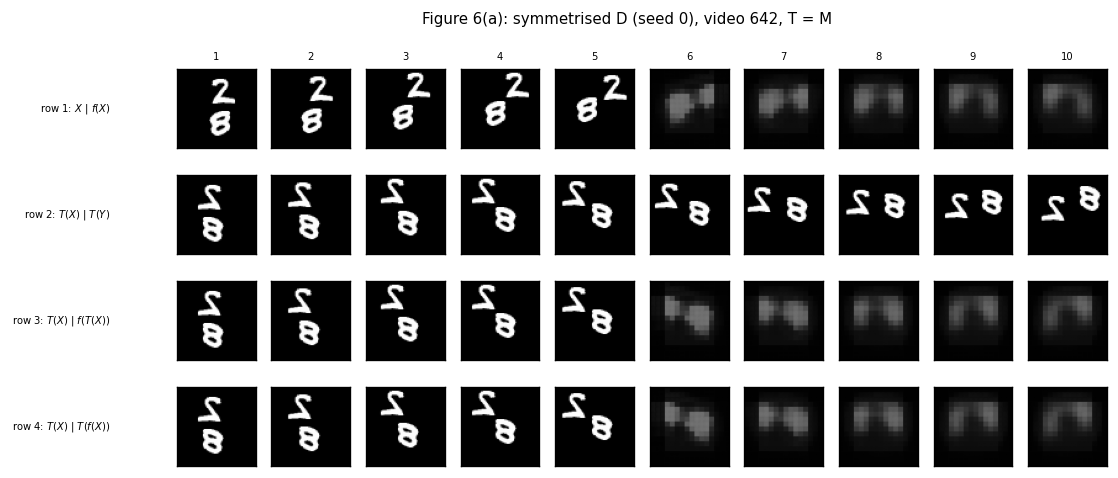

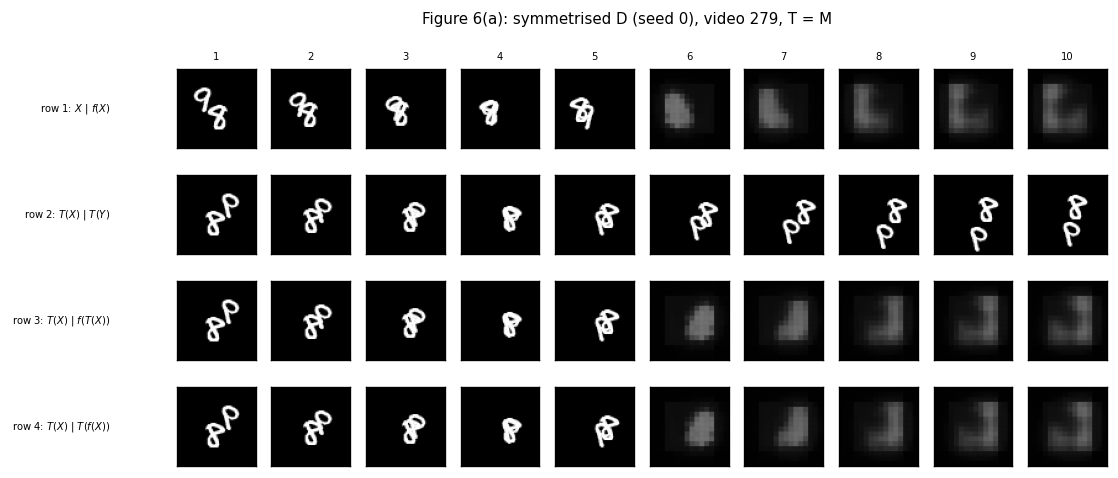

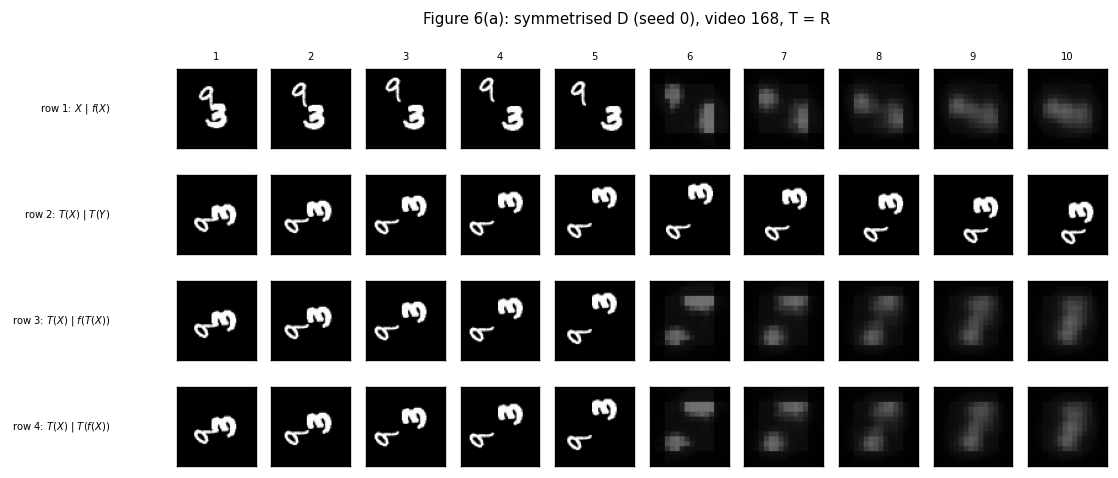

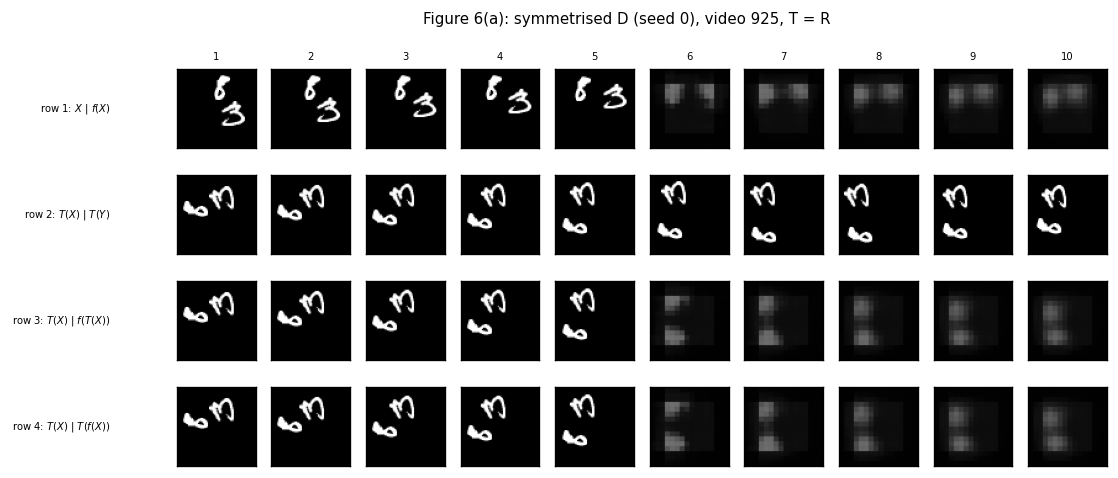

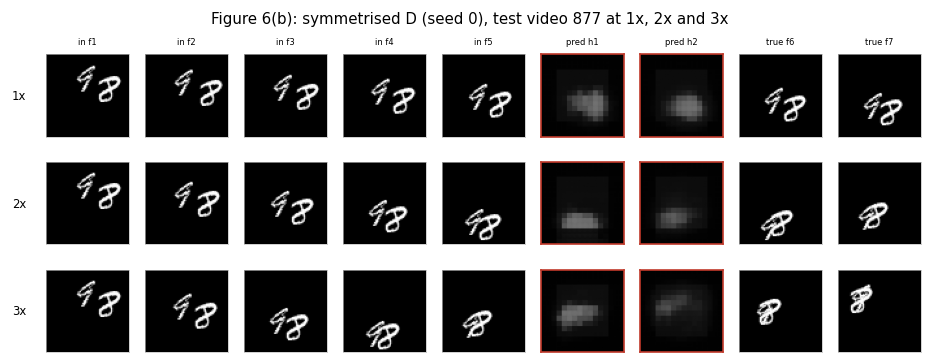

In [20]:
final_f = Symmetrised(TRAINED[(FINAL_NAME, 0)])

for idx, which in FIG3_CASES:
    panel = consistency_panel(final_f, test_videos, idx, which)
    tag = f"v{idx}_{which}"
    draw_panel(panel, f"Figure 6(a): symmetrised {FINAL_NAME} (seed 0), video {idx}, T = {which}",
               FIGS / f"fig6a_{tag}.pdf")
    write_panel_gif(panel, GIFS / f"fig6a_{tag}.gif")

draw_speed_figure(final_f, FIG5_IDX,
                  f"Figure 6(b): symmetrised {FINAL_NAME} (seed 0), test video {FIG5_IDX} "
                  f"at 1x, 2x and 3x", FIGS / "fig6b_speeds.pdf")

### Collected results

In [21]:
summary = {
    "hardware": HARDWARE,
    "torch": torch.__version__,
    "smoke": SMOKE,
    "epochs": EPOCHS,
    "seeds": list(SEEDS),
    "models": {k: {"label": v["label"], "protocol": v["protocol"], "symmetry": v["symmetry"]}
               for k, v in MODELS.items()},
    "architecture": {"A_params": A_PARAMS, "D_params": D_PARAMS,
                     "A_reach_px": reach_pixels(4, (1, 1)),
                     "D_reach_px": reach_pixels(4, (1, 3))},
    "flow": flow_stats,
    "figure2_videos": [int(i) for i in fig2_idx],
    "figure3_cases": FIG3_CASES,
    "figure5_video": FIG5_IDX,
    "final_model": f"symmetrised {FINAL_NAME}",
    "epoch_seconds": {f"{n}_s{s}": META[(n, s)]["mean_epoch_seconds"]
                      for n in MODELS for s in SEEDS},
    "table2": table2_rows,
    "table3": table3_rows,
    "table4": {"E2": speed_A, "E5": e5_A},
    "table5": {"header": TABLE5_HEADER, "rows": table5_rows},
    "table6": {"header": TABLE5_HEADER, "rows": table6_rows},
}
save_json("summary.json", summary)

print("figures:", sorted(p.name for p in FIGS.iterdir()))
print("gifs   :", sorted(p.name for p in GIFS.iterdir()))
print("runs   :", sorted(p.name for p in RUNS.iterdir()))

wrote /kaggle/working/results/summary.json
figures: ['fig1_optical_flow.pdf', 'fig1_optical_flow.png', 'fig2_predictions.pdf', 'fig2_predictions.png', 'fig3_v168_R.pdf', 'fig3_v168_R.png', 'fig3_v279_M.pdf', 'fig3_v279_M.png', 'fig3_v642_M.pdf', 'fig3_v642_M.png', 'fig3_v925_R.pdf', 'fig3_v925_R.png', 'fig4_consistency_hist.pdf', 'fig4_consistency_hist.png', 'fig5_speeds.pdf', 'fig5_speeds.png', 'fig6a_v168_R.pdf', 'fig6a_v168_R.png', 'fig6a_v279_M.pdf', 'fig6a_v279_M.png', 'fig6a_v642_M.pdf', 'fig6a_v642_M.png', 'fig6a_v925_R.pdf', 'fig6a_v925_R.png', 'fig6b_speeds.pdf', 'fig6b_speeds.png']
gifs   : ['fig3_v168_R.gif', 'fig3_v279_M.gif', 'fig3_v642_M.gif', 'fig3_v925_R.gif', 'fig6a_v168_R.gif', 'fig6a_v279_M.gif', 'fig6a_v642_M.gif', 'fig6a_v925_R.gif']
runs   : ['A_s0.pt', 'A_s1.pt', 'B_s0.pt', 'B_s1.pt', 'C_s0.pt', 'C_s1.pt', 'D_s0.pt', 'D_s1.pt']


In [22]:
import os
import zipfile
from IPython.display import FileLink

root_dir = '/kaggle/working'
archive_name = os.path.join(root_dir, 'output_bundle.zip')
exclude_folder = os.path.join(root_dir, 'data')

with zipfile.ZipFile(archive_name, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for foldername, subfolders, filenames in os.walk(root_dir):
        # Skip the data directory and anything inside it
        if foldername == exclude_folder or foldername.startswith(exclude_folder + os.sep):
            continue
        
        for filename in filenames:
            file_path = os.path.join(foldername, filename)
            # Avoid archiving the output zip itself
            if file_path == archive_name:
                continue
            
            arcname = os.path.relpath(file_path, root_dir)
            zipf.write(file_path, arcname)

FileLink('output_bundle.zip')

/kaggle/working/output_bundle.zip